# 과제3 — 한국 음식 이미지 전이학습 비교 (CPU)
**202435119 한여원**

## 목적·데이터 선정
한국 음식 이미지 중 김밥·만두·피자·식혜·콩자반 5종을 분류한다. 색·질감·형태가 다양한 RGB 사진이라 ImageNet 사전학습 특징의 재사용을 비교하기 적합하다. 클래스는 결과를 보기 전에 고정한다. 소규모 CPU 실험으로 전이학습이 항상 이긴다는 가정은 하지 않는다.

출처: AI Hub 한국 음식 이미지, 사용자가 내려받은 kfood 배포본. ZIP의 상위 음식군(밥/면 등)이 아니라 **하위 음식명 폴더를 정답으로 사용**한다. 배포 파일과 사진 저작권·이용 조건을 준수한다. 공식 출처: [AI Hub 한국 이미지(음식)](https://aihub.or.kr/aihubdata/data/view.do?dataSetSn=79).

## 실행
기존 Python 가상환경을 Jupyter/VS Code 커널로 선택한 뒤 위에서 아래로 실행한다. CPU 전용이며 GPU 설정이 필요 없다. 데이터 ZIP은 그대로 두고, 자동으로 선택 이미지만 출력 폴더에 추출한다. 기본 클래스당 학습 100·검증 30·테스트 50장, 입력 128픽셀, 네 방식 각각 5에폭이다.

별도의 확인 플래그 없이 실행된다. 데이터 누락·표본 부족·손상은 구체적인 오류를 표시한다. 전체 실행에는 시간이 걸리며 학습 셀에서 에폭별 진행 상황이 출력된다. 본 파일에는 실행 결과가 저장되어 있으며, 재실행하면 실행 환경에 따라 시간과 수치가 달라질 수 있다.

사진에는 음식 외 그릇·글자·배경 및 다른 음식이 함께 나타날 수 있다. 폴더 라벨을 사용하되 이러한 배경 의존성과 라벨 모호성을 결과의 한계로 고려한다.

수업의 포도 잎 데이터와 다른 음식 사진을 선택하여 새로운 분류 과제로 전이학습을 적용하였다. 배포본의 전체 이미지 목록에서는 150개 음식 클래스가 확인되지만, CPU에서 네 방식을 반복 비교할 수 있도록 서로 다른 외형을 가진 5종으로 범위를 제한했다. 김밥의 단면, 만두의 형태, 피자의 토핑, 식혜의 액체·밥알, 콩자반의 질감처럼 다양한 시각적 특징을 포함한다. 따라서 이번 결과는 전체 150종 인식 성능이 아니라 미리 선정한 5종의 분류 성능이다.

In [1]:
from pathlib import Path, PurePosixPath
import os,json,time,random,hashlib,zipfile,io,copy,platform
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image,ImageOps
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torchvision import models,transforms
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report

DATA_ROOT=Path(r'D:\hanyeowon\가천대학교\기계학습프로그래밍\data\한국 음식 이미지\kfood')
OUTPUT_DIR=Path.cwd()/'assignment3_food_results'
DATA_SOURCE_URL='https://aihub.or.kr/aihubdata/data/view.do?dataSetSn=79'
CLASS_NAMES=['김밥','만두','피자','식혜','콩자반']
DISPLAY_NAMES=['Gimbap','Dumplings','Pizza','Sikhye','Braised beans']
N_TRAIN,N_VAL,N_TEST=100,30,50
IMAGE_SIZE=128
BATCH_SIZE=16
EPOCHS=5
SEED=42
THREADS=min(8,os.cpu_count() or 4)
device=torch.device('cpu')
torch.set_num_threads(THREADS)
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
CACHE=OUTPUT_DIR/'selected_images';CACHE.mkdir(exist_ok=True)
def seed_all():
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
seed_all()
plt.rcParams['font.family']='Malgun Gothic' if os.name=='nt' else 'DejaVu Sans'
plt.rcParams['axes.unicode_minus']=False
print('장치:',device,'torch:',torch.__version__,'threads:',THREADS)
print('결과 위치:',OUTPUT_DIR.resolve())

장치: cpu torch: 2.14.1+cpu threads: 8
결과 위치: D:\hanyeowon\가천대학교\기계학습프로그래밍\assignment\assignment3\assignment3_food_results


## 1. ZIP 검사·이미지 검사·분할
ZIP 전체의 이미지 목록을 조사한다. 선택 음식은 무작위 순서로 검사하여 EXIF 회전 보정 후 RGB로 변환한다. 픽셀 해시로 완전 중복을 제거하고 16×16 평균 해시가 같은 이미지는 보수적으로 한 장만 사용한다(유사 이미지 탐지의 완전성을 보장하지 않음). 클래스가 다른 동일 후보도 중복으로 제외하며 기록을 남긴다. 학습/검증/테스트 분할 전에 검사한다. 촬영자·출처 그룹 정보는 제공된 폴더만으로 알 수 없어 파일 단위 분할의 한계로 보고한다.

한 음식군 ZIP에 여러 음식이 들어 있으므로 ZIP 이름을 라벨로 사용하지 않는다. 원본 전체를 해제하지 않고 선택 사진을 PNG로 저장한다. 이전 실행의 캐시가 남아 있어도 현재 생성한 목록만 읽는다.

실제 사용량은 클래스마다 학습 100장·검증 30장·테스트 50장으로, 전체 학습 500장·검증 150장·테스트 250장, 총 900장이다. 클래스별 수량을 같게 하여 특정 음식의 빈도가 결과를 지배하지 않게 했다. 고정 시드 42로 분할하고 네 방식이 동일한 목록을 사용한다. 학습 세트는 가중치 갱신, 검증 세트는 최적 에폭과 방식 선택, 테스트 세트는 모든 학습·선택이 끝난 뒤의 최종 평가에만 사용한다. 저장된 실행에서는 후보 10장이 제외되었으며, 이는 전체 원본이 아닌 선택 과정에서 검사한 후보에 대한 결과이다.

,available_images
class,
가지볶음,1000
간장게장,1001
갈비구이,1000
갈비찜,1000
갈비탕,1000
...,...
홍어무침,1000
황태구이,1000
회무침,1004


김밥 : 180 장 준비
만두 : 180 장 준비
피자 : 180 장 준비
식혜 : 180 장 준비
콩자반 : 180 장 준비


split,test,train,val
class,,,
김밥,50,100,30
만두,50,100,30
식혜,50,100,30
콩자반,50,100,30
피자,50,100,30


제외된 후보: 10 전체 원본이 아닌 선택 후보를 검사한 결과입니다.


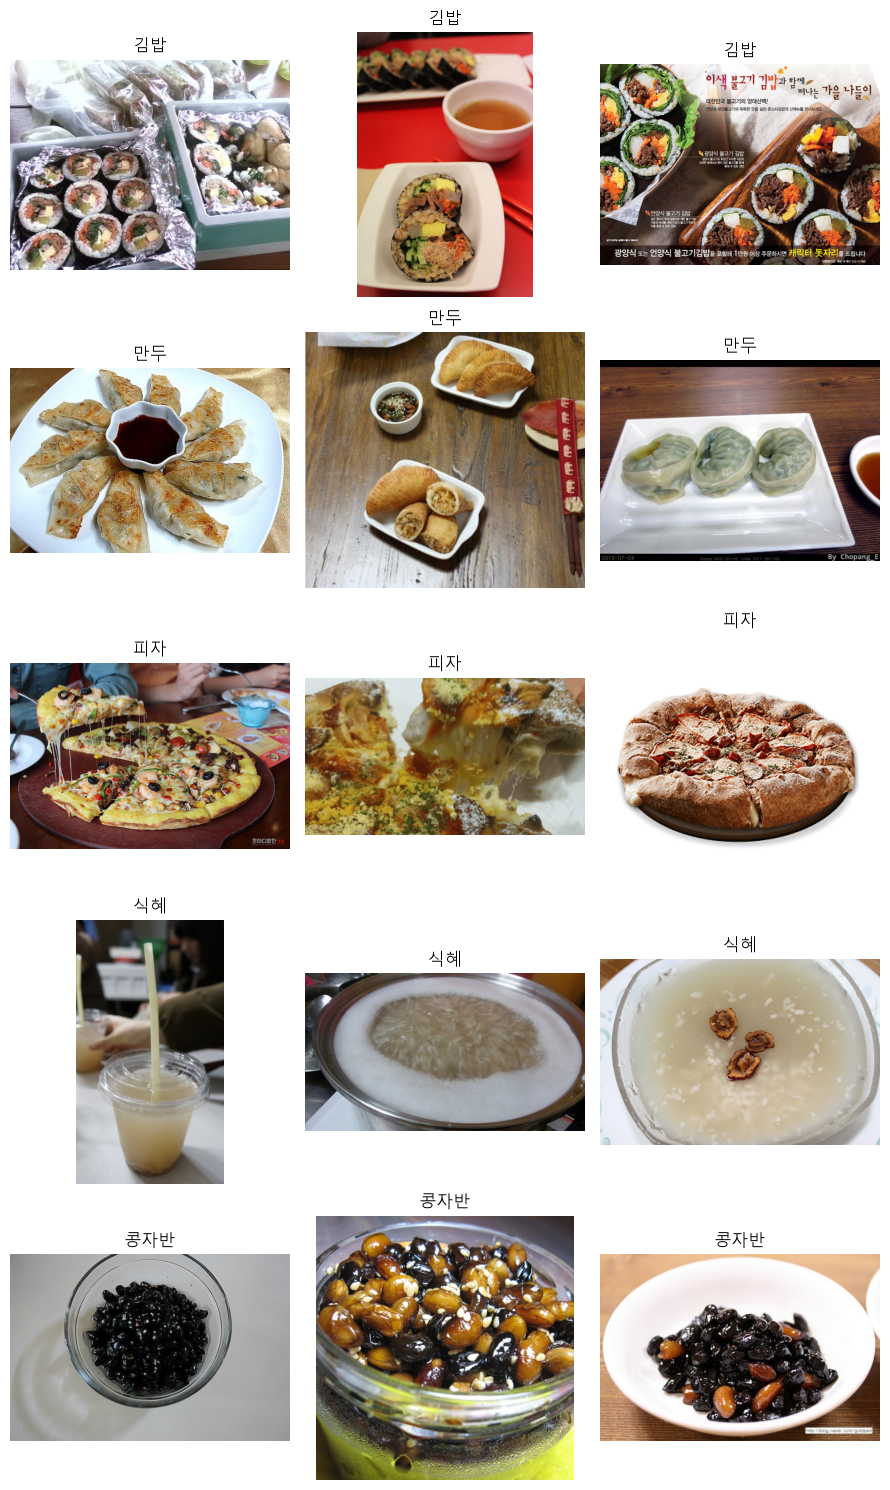

In [2]:
assert DATA_ROOT.is_dir(), f'데이터 폴더가 없습니다: {DATA_ROOT}'
zips=sorted(DATA_ROOT.rglob('*.zip'));assert zips,'ZIP이 없습니다.'
catalog=[]
for zp in zips:
    with zipfile.ZipFile(zp) as z:
        for info in z.infolist():
            p=PurePosixPath(info.filename.replace(chr(92),'/'))
            if info.is_dir() or p.suffix.lower() not in ('.jpg','.jpeg','.png','.bmp','.webp'):continue
            catalog.append({'zip':str(zp),'member':info.filename,'class':p.parent.name})
catalog=pd.DataFrame(catalog)
display(catalog.groupby('class').size().rename('available_images').to_frame())
assert set(CLASS_NAMES)<=set(catalog['class']), f'선택 음식 누락: {set(CLASS_NAMES)-set(catalog["class"])}'
rows=[];rejected=[];seen_pixels=set();seen_approx=set()
needed=N_TRAIN+N_VAL+N_TEST
for label,name in enumerate(CLASS_NAMES):
    candidates=catalog[catalog['class']==name].sample(frac=1,random_state=SEED)
    accepted=[];handles={}
    try:
        for item in candidates.itertuples():
            try:
                if item.zip not in handles:handles[item.zip]=zipfile.ZipFile(item.zip)
                content=handles[item.zip].read(item.member)
                with Image.open(io.BytesIO(content)) as im:
                    im=ImageOps.exif_transpose(im)
                    if im.mode in ('P','RGBA','LA'):
                        rgba=im.convert('RGBA');background=Image.new('RGBA',rgba.size,'white');background.alpha_composite(rgba);im=background.convert('RGB')
                    else: im=im.convert('RGB')
                    im.load()
                    assert min(im.size)>=32,'너무 작은 이미지'
                    pixel_hash=hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest()
                    small=np.asarray(im.convert('L').resize((16,16)),dtype=np.float32)
                    approx=np.packbits(small>small.mean()).tobytes().hex()
                    if pixel_hash in seen_pixels or approx in seen_approx:
                        rejected.append({'class':name,'member':item.member,'reason':'duplicate hash'});continue
                    target=CACHE/f'{label}_{len(accepted):04d}_{pixel_hash[:12]}.png'
                    im.save(target)
                seen_pixels.add(pixel_hash);seen_approx.add(approx)
                accepted.append({'path':str(target),'class':name,'label':label,'zip':item.zip,'member':item.member,'pixel_hash':pixel_hash,'approx_hash':approx})
                if len(accepted)==needed:break
            except Exception as e:
                rejected.append({'class':name,'member':item.member,'reason':str(e)})
    finally:
        for z in handles.values():z.close()
    assert len(accepted)==needed, f'{name}: 정상·중복제거 이미지 {len(accepted)}장 / 필요 {needed}장. 수량 설정을 줄이세요.'
    order=np.random.default_rng(SEED).permutation(len(accepted))
    for i,index in enumerate(order):
        r=accepted[index];r['split']='train' if i<N_TRAIN else 'val' if i<N_TRAIN+N_VAL else 'test';rows.append(r)
    print(name,':',len(accepted),'장 준비')
data=pd.DataFrame(rows)
assert data.groupby('pixel_hash').split.nunique().max()==1
assert data.groupby('approx_hash').split.nunique().max()==1
data.to_csv(OUTPUT_DIR/'split_manifest.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(rejected,columns=['class','member','reason']).to_csv(OUTPUT_DIR/'excluded_images.csv',index=False,encoding='utf-8-sig')
display(pd.crosstab(data['class'],data.split))
print('제외된 후보:',len(rejected),'전체 원본이 아닌 선택 후보를 검사한 결과입니다.')
fig,axes=plt.subplots(len(CLASS_NAMES),3,figsize=(9,3*len(CLASS_NAMES)))
for label in range(len(CLASS_NAMES)):
    examples=data[(data.label==label)&(data.split=='train')].head(3)
    for ax,r in zip(axes[label],examples.itertuples()):
        ax.imshow(Image.open(r.path));ax.set_title(CLASS_NAMES[label]);ax.axis('off')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'training_examples.png',dpi=140);plt.show()

## 2. 입력·모델·학습 조건
비율을 유지해 짧은 변을 144로 조정하고 128×128로 자른다. 학습은 무작위 자르기·좌우 반전, 검증/테스트는 중앙 자르기만 사용한다. ImageNet 평균/표준편차로 정규화한다. 입력 축소는 CPU 비용을 줄이나 세부 음식 정보가 줄어들 수 있다.

| 방식 | 초기화 | 학습 범위 | 학습률 |
|---|---|---|---|
| Scratch | 무작위 | 전체 ResNet18 | 0.001 |
| 특징 추출 | ImageNet | fc만 | 0.001 |
| 부분 미세조정 | ImageNet | layer4+fc | layer4 0.0001 / fc 0.001 |
| 전체 미세조정 | ImageNet | 전체 | 몸통 0.0001 / fc 0.001 |

과제의 layer4+fc 조건에 맞춰 동일한 ResNet18을 비교한다. 동일 데이터 분할·최대 에폭·배치 크기·시드를 사용한다. 사전학습 몸통은 작은 학습률로 기존 특징의 큰 변화를 제한한다. 동결된 BatchNorm 통계도 고정한다. 검증 Macro-F1 최고 에폭을 저장하고 테스트는 마지막 비교에만 사용한다. 짧은 동일 학습 예산의 비교이며 Scratch의 충분히 수렴한 최대 성능과의 비교는 아니다.

### 사전학습 모델과 새 분류층
ResNet18은 더 깊은 ResNet 계열에 비해 규모가 작고, layer4와 fc를 구분하여 학습 범위를 명확하게 설정할 수 있어 CPU 비교 실험에 선택했다. 잔차 연결을 사용하는 CNN이며 torchvision의 ImageNet1K V1 사전학습 가중치를 사용한다. 기존 모델의 1,000개 클래스용 분류층은 그대로 쓸 수 없으므로 512차원 특징을 음식 5종 점수로 바꾸는 새 Linear(512, 5) 층으로 교체했다. 새 분류층은 무작위로 초기화되며 음식 사진으로 학습한다. 전이하는 것은 김밥 등의 정답 자체가 아니라 기존 모델이 배운 색·경계·질감·형태의 표현이다. Scratch는 같은 구조를 쓰되 몸통까지 무작위 초기화하여 이 사전학습 효과를 비교하는 기준이다.

특징 추출에서는 fc 이외의 모든 파라미터를 동결한다. 부분 미세조정에서는 conv1과 layer1~3을 동결하고 layer4와 fc만 갱신한다. 전체 미세조정은 모든 층을 갱신한다. 새 fc는 목표 클래스에 맞는 판단 기준을 처음 배워야 하므로 학습률 0.001을 사용하고, 사전학습 몸통은 기존 특징을 보존하면서 조정하도록 0.0001을 사용했다. Scratch에는 0.001을 적용했다. 이는 이번 실험의 고정 설정이지 각 방식에 대한 최적 학습률 탐색 결과는 아니다.

### 정규화와 공통 학습 설정
원본 해상도와 종횡비가 달라 비율 유지 Resize 후 Crop으로 입력을 통일한다. ToTensor로 픽셀을 0~255에서 0~1로 변환한 다음, RGB 채널별로 (픽셀값−평균)/표준편차를 계산한다. 평균은 [0.485, 0.456, 0.406], 표준편차는 [0.229, 0.224, 0.225]이며 사전학습 모델의 입력 기준에 맞춘 고정값이다. 검증·테스트에서 통계를 추정하지 않는다. Scratch에도 같은 전처리를 적용해 입력 조건을 맞춘다. 무작위 증강은 학습에만 적용하여 평가 이미지는 매번 같은 방식으로 처리한다.

네 방식 모두 배치 16, 최대 5에폭, AdamW(weight decay=0.0001), CrossEntropyLoss를 사용한다. 손실에는 Softmax 이전의 클래스 점수를 입력한다. 클래스 가중치는 학습 수량으로만 계산하며 이번에는 각 클래스가 100장으로 같아 모두 1이다. 재현성을 위해 시드를 고정하지만 라이브러리 버전·하드웨어에 따른 차이는 남을 수 있다.

In [4]:
MEAN=[.485,.456,.406]; STD=[.229,.224,.225]
train_tf=transforms.Compose([transforms.Resize(IMAGE_SIZE+16),transforms.RandomCrop(IMAGE_SIZE),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
eval_tf=transforms.Compose([transforms.Resize(IMAGE_SIZE+16),transforms.CenterCrop(IMAGE_SIZE),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
class FoodDataset(Dataset):
    def __init__(self,frame,transform): self.frame=frame.reset_index(drop=True);self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        with Image.open(row.path) as im: x=self.transform(im.convert('RGB'))
        return x,int(row.label)
def worker_seed(worker_id):
    s=torch.initial_seed()%2**32; np.random.seed(s);random.seed(s)
def loader(split,train=False):
    gen=torch.Generator().manual_seed(SEED)
    return DataLoader(FoodDataset(data[data.split==split],train_tf if train else eval_tf),batch_size=BATCH_SIZE,
                      shuffle=train,num_workers=0,pin_memory=(device.type=='cuda'),worker_init_fn=worker_seed,generator=gen)

counts=np.bincount(data[data.split=='train'].label,minlength=len(CLASS_NAMES))
class_weights=torch.tensor(counts.sum()/(len(CLASS_NAMES)*counts),dtype=torch.float32,device=device)
loss_fn=nn.CrossEntropyLoss(weight=class_weights)
def make_model(mode):
    seed_all()
    model=models.resnet18(weights=None if mode=='scratch' else models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc=nn.Linear(model.fc.in_features,len(CLASS_NAMES))
    for name,p in model.named_parameters():
        p.requires_grad=(mode in ('scratch','full') or name.startswith('fc.') or (mode=='partial' and name.startswith('layer4.')))
    model=model.to(device)
    if mode in ('scratch','feature'):
        params=[{'params':[p for p in model.parameters() if p.requires_grad],'lr':1e-3}]
    else:
        params=[{'params':[p for n,p in model.named_parameters() if p.requires_grad and not n.startswith('fc.')],'lr':1e-4},
                {'params':model.fc.parameters(),'lr':1e-3}]
    return model,torch.optim.AdamW(params,weight_decay=1e-4)
def training_mode(model,mode):
    model.train()
    if mode in ('feature','partial'):
        model.eval();model.fc.train()
        if mode=='partial': model.layer4.train()
def evaluate(model,dl):
    model.eval(); probs=[];truth=[];loss_sum=0.;weight_sum=0.
    with torch.no_grad():
        for x,y in dl:
            x,y=x.to(device),y.to(device)
            logits=model(x); denom=class_weights[y].sum().item()
            loss_sum+=loss_fn(logits,y).item()*denom;weight_sum+=denom
            probs.append(logits.softmax(1).cpu().numpy());truth.extend(y.cpu().tolist())
    probs=np.concatenate(probs);truth=np.array(truth);pred=probs.argmax(1)
    return {'loss':loss_sum/weight_sum,'accuracy':accuracy_score(truth,pred),
            'macro_f1':f1_score(truth,pred,labels=list(range(len(CLASS_NAMES))),average='macro',zero_division=0)},truth,probs

## 3. 네 방식 학습
처음 사전학습 가중치를 다운로드할 때 인터넷이 필요하다. 실패하면 자동으로 무작위 가중치로 대체하지 않는다. 시간에는 학습·매 에폭 검증·로컬 저장이 포함되고 가중치 다운로드와 최종 테스트는 제외된다. 첫 에폭 종료 시 남은 학습의 대략적인 시간을 출력한다. CPU 전용이므로 다른 무거운 작업은 줄이고 전원을 연결한다.

In [5]:
MODES=['scratch','feature','partial','full']
histories={};records=[]
for mode in MODES:
    model,opt=make_model(mode)
    train_dl=loader('train',True);val_dl=loader('val')
    params=sum(p.numel() for p in model.parameters() if p.requires_grad)
    checkpoint=OUTPUT_DIR/f'{mode}_best.pt'
    history=[];best=-1.;best_epoch=0;start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        training_mode(model,mode);total_loss=0.;total=0;truth=[];preds=[]
        for x,y in train_dl:
            opt.zero_grad(set_to_none=True);logits=model(x);loss=loss_fn(logits,y);loss.backward();opt.step()
            total_loss+=loss.item()*len(y);total+=len(y)
            truth.extend(y.tolist());preds.extend(logits.detach().argmax(1).tolist())
        val,_,_=evaluate(model,val_dl)
        row={'epoch':epoch,'train_loss':total_loss/total,'train_accuracy':accuracy_score(truth,preds),
             'val_loss':val['loss'],'val_accuracy':val['accuracy'],'val_macro_f1':val['macro_f1']}
        history.append(row)
        if val['macro_f1']>best:
            best=val['macro_f1'];best_epoch=epoch;torch.save(model.state_dict(),checkpoint)
        elapsed=time.perf_counter()-start
        print(f'{mode} epoch {epoch}/{EPOCHS} | train acc={row["train_accuracy"]:.3f} val F1={val["macro_f1"]:.3f} | elapsed={elapsed/60:.1f} min | remaining~{elapsed/epoch*(EPOCHS-epoch)/60:.1f} min',flush=True)
    seconds=time.perf_counter()-start
    histories[mode]=pd.DataFrame(history);histories[mode].to_csv(OUTPUT_DIR/f'{mode}_history.csv',index=False)
    records.append({'mode':mode,'trainable_parameters':params,'training_seconds':seconds,'best_epoch':best_epoch,'best_val_macro_f1':best})
    del model,opt
comparison=pd.DataFrame(records)
best_mode=comparison.sort_values('best_val_macro_f1',ascending=False,kind='stable').iloc[0]['mode']
print('검증으로 선택한 최고 방식:',best_mode)
# 모든 학습 및 선택 완료 후 테스트. 이 결과를 보고 설정을 다시 고르지 않는다.
test_frame=data[data.split=='test'].reset_index(drop=True)
predictions={}
for mode in MODES:
    model=models.resnet18(weights=None);model.fc=nn.Linear(model.fc.in_features,len(CLASS_NAMES))
    model.load_state_dict(torch.load(OUTPUT_DIR/f'{mode}_best.pt',map_location='cpu',weights_only=True))
    metrics,y,prob=evaluate(model,loader('test'))
    for key in ['accuracy','macro_f1']:comparison.loc[comparison['mode']==mode,'test_'+key]=metrics[key]
    frame=test_frame.copy();frame['prediction']=prob.argmax(1)
    for k in range(len(CLASS_NAMES)):frame[f'p{k}']=prob[:,k]
    predictions[mode]=frame;frame.to_csv(OUTPUT_DIR/f'{mode}_test_predictions.csv',index=False,encoding='utf-8-sig')
    del model
comparison.to_csv(OUTPUT_DIR/'comparison.csv',index=False)
display(comparison)

scratch epoch 1/5 | train acc=0.504 val F1=0.429 | elapsed=0.3 min | remaining~1.4 min
scratch epoch 2/5 | train acc=0.606 val F1=0.582 | elapsed=0.9 min | remaining~1.3 min
scratch epoch 3/5 | train acc=0.612 val F1=0.492 | elapsed=1.6 min | remaining~1.0 min
scratch epoch 4/5 | train acc=0.520 val F1=0.552 | elapsed=2.2 min | remaining~0.5 min
scratch epoch 5/5 | train acc=0.642 val F1=0.680 | elapsed=2.9 min | remaining~0.0 min
feature epoch 1/5 | train acc=0.606 val F1=0.883 | elapsed=0.4 min | remaining~1.5 min
feature epoch 2/5 | train acc=0.922 val F1=0.933 | elapsed=0.6 min | remaining~0.9 min
feature epoch 3/5 | train acc=0.940 val F1=0.921 | elapsed=0.8 min | remaining~0.5 min
feature epoch 4/5 | train acc=0.938 val F1=0.947 | elapsed=1.1 min | remaining~0.3 min
feature epoch 5/5 | train acc=0.964 val F1=0.940 | elapsed=1.5 min | remaining~0.0 min
partial epoch 1/5 | train acc=0.780 val F1=0.946 | elapsed=0.5 min | remaining~2.0 min
partial epoch 2/5 | train acc=0.950 val F1=

,mode,trainable_parameters,training_seconds,best_epoch,best_val_macro_f1,test_accuracy,test_macro_f1
0,scratch,11179077,171.897966,5,0.679645,0.664,0.655318
1,feature,2565,90.408479,4,0.946724,0.940,0.939983
2,partial,8396293,127.604309,5,0.973521,0.956,0.956279
3,full,11179077,199.837129,5,0.973217,0.952,0.952118


## 4. 비교표·학습곡선·혼동행렬·예측 사례
학습 정확도는 갱신 전 배치 예측의 누적값이다. 검증은 에폭 종료 모델을 사용한다. 최고 모델은 테스트가 아니라 검증 지표로 선정했다. 한 시드 실험이라 작은 차이의 통계적 우월성을 주장하지 않는다.

Accuracy는 전체 평가 이미지 중 정답 비율이다. Macro-F1은 각 음식 클래스의 정밀도와 재현율로 F1을 계산한 뒤 동일한 비중으로 평균한 값으로, 특정 클래스에서만 성능이 낮은지 함께 살피기 위해 사용한다. 비교표의 학습 파라미터 수는 모델 전체 크기가 아니라 실제로 갱신하는 파라미터 수이다. 특징 추출도 몸통의 순전파 연산은 필요하므로 파라미터 감소율만큼 시간이 줄어들지는 않는다. 학습 시간은 같은 CPU에서 측정했지만 시스템 부하와 발열에 영향을 받을 수 있다.

학습 곡선에서는 손실 감소와 검증 F1의 안정성을 함께 확인한다. 혼동행렬은 행이 실제 클래스, 열이 예측 클래스이며 대각선이 정답 수이다. 예측 사진 12장은 고정 시드로 뽑은 테스트 예시로, 맞힌 사진만 골라 제시하지 않았다.

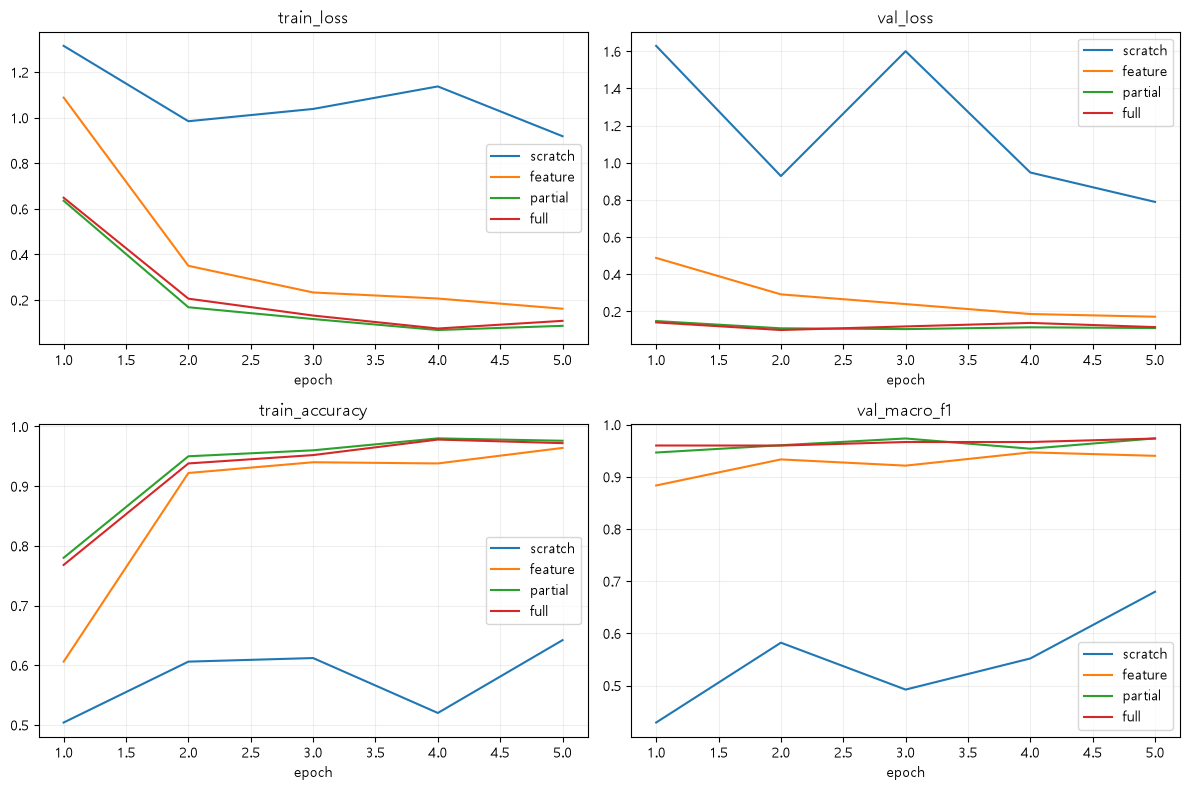

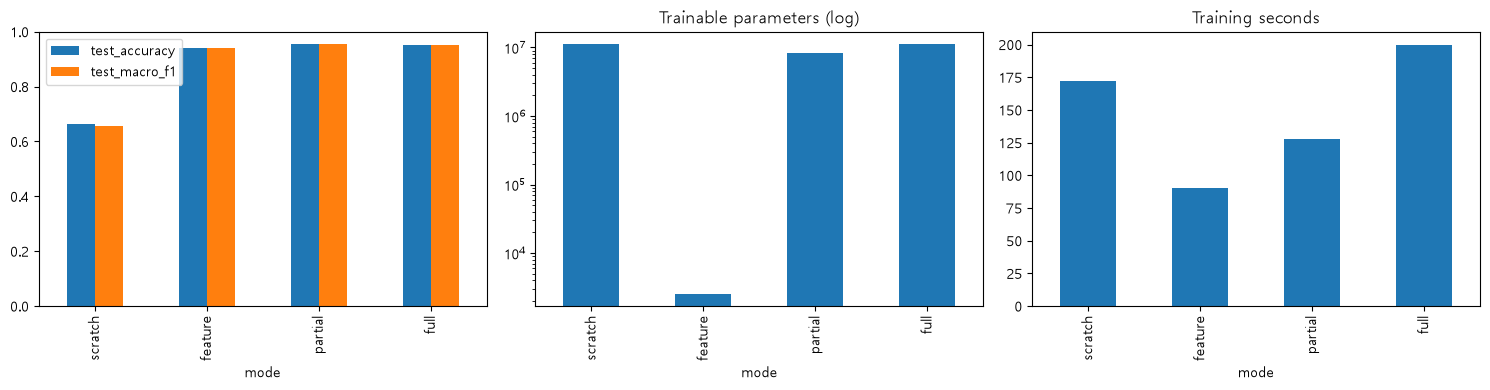

              precision    recall  f1-score   support

          김밥       0.90      0.94      0.92        50
          만두       0.91      0.98      0.94        50
          피자       0.98      0.94      0.96        50
          식혜       1.00      1.00      1.00        50
         콩자반       1.00      0.92      0.96        50

    accuracy                           0.96       250
   macro avg       0.96      0.96      0.96       250
weighted avg       0.96      0.96      0.96       250



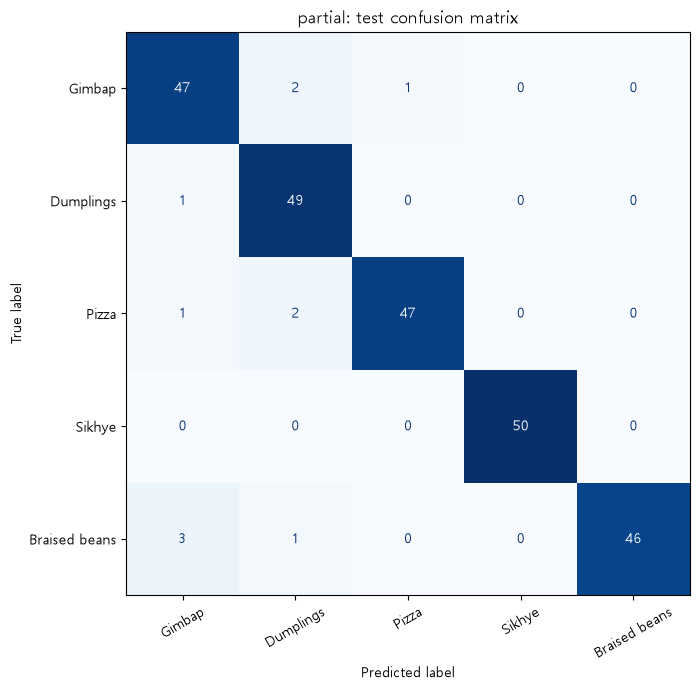

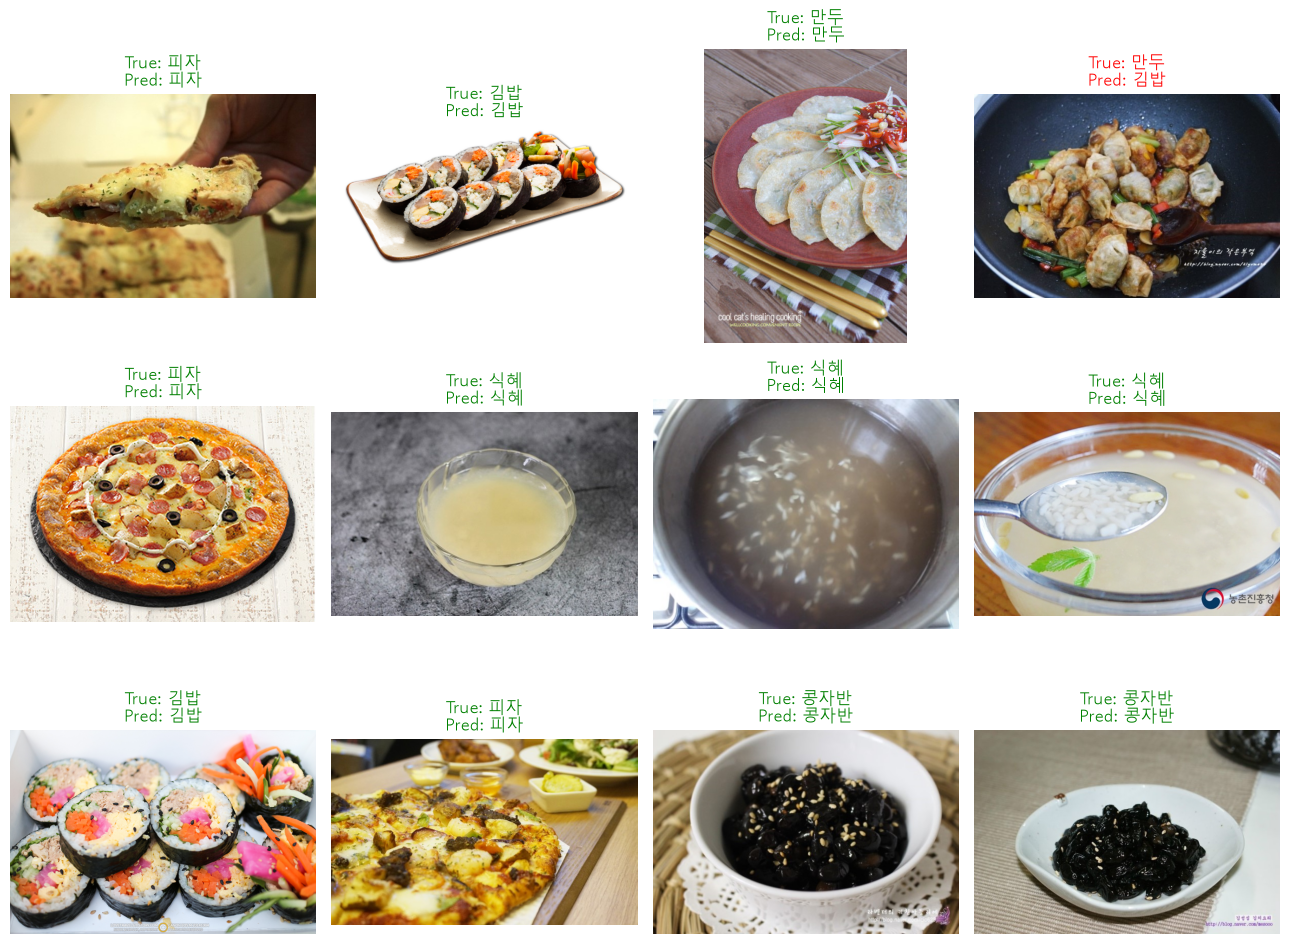

In [7]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for mode,h in histories.items():
    for ax,key in zip(axes.flat,['train_loss','val_loss','train_accuracy','val_macro_f1']):ax.plot(h.epoch,h[key],label=mode);ax.set_title(key);ax.set_xlabel('epoch');ax.grid(alpha=.2)
for ax in axes.flat:ax.legend()
plt.tight_layout();plt.savefig(OUTPUT_DIR/'learning_curves.png',dpi=150);plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
comparison.set_index('mode')[['test_accuracy','test_macro_f1']].plot.bar(ax=axes[0],ylim=(0,1))
comparison.plot.bar(x='mode',y='trainable_parameters',ax=axes[1],logy=True,legend=False,title='Trainable parameters (log)')
comparison.plot.bar(x='mode',y='training_seconds',ax=axes[2],legend=False,title='Training seconds')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'comparison.png',dpi=150);plt.show()
frame=predictions[best_mode]
print(classification_report(frame.label,frame.prediction,labels=list(range(len(CLASS_NAMES))),target_names=CLASS_NAMES,zero_division=0))
fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(confusion_matrix(frame.label,frame.prediction,labels=list(range(len(CLASS_NAMES)))),display_labels=DISPLAY_NAMES).plot(ax=ax,cmap='Blues',colorbar=False,xticks_rotation=30)
ax.set_title(f'{best_mode}: test confusion matrix')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'confusion_matrix.png',dpi=150);plt.show()
examples=frame.sample(min(12,len(frame)),random_state=SEED)
assert len(examples)>=8
fig,axes=plt.subplots(3,4,figsize=(13,10))
for ax,row in zip(axes.flat,examples.itertuples()):
    ax.imshow(Image.open(row.path));ax.set_title(f'True: {CLASS_NAMES[row.label]}\nPred: {CLASS_NAMES[row.prediction]}',color='green' if row.label==row.prediction else 'red');ax.axis('off')
for ax in list(axes.flat)[len(examples):]:ax.axis('off')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'test_predictions.png',dpi=150);plt.show()

## 5. 결과 분석과 결론 (실행 지표 기반)
실제 결과에 따라 향상·하락을 모두 보고한다. 성능을 높이기 위해 테스트 분할을 반복 변경하지 않는다. 다음 해석은 이 노트북에 저장된 실행 결과를 기준으로 한다.

### 성능과 계산 비용의 해석
Scratch의 테스트 정확도는 66.4%, Macro-F1은 0.6553이었다. 특징 추출은 94.0%와 0.9400, 부분 미세조정은 95.6%와 0.9563, 전체 미세조정은 95.2%와 0.9521을 기록했다. 부분 미세조정은 Scratch보다 정확도가 29.2%p 높았다. 검증 Macro-F1도 부분 미세조정 0.973521이 전체 미세조정 0.973217보다 약간 높아 partial을 최종 방식으로 선택했다. 두 방식의 테스트 정확도 차이 0.4%p는 250장 중 한 장 차이이므로 일반적인 우열을 단정하기는 어렵다.

현재 저장된 실행에서 학습 시간은 Scratch 약 171.9초, 특징 추출 90.4초, 부분 미세조정 127.6초, 전체 미세조정 199.8초였다. 특징 추출은 2,565개 파라미터만 갱신하면서 94.0%의 정확도를 얻어, 이 환경에서 속도와 성능의 균형이 좋았다. 부분 미세조정은 8,396,293개를 갱신하여 조금 더 높은 성능을 얻었고, 전체 미세조정은 11,179,077개를 갱신했지만 추가 비용에 비례한 성능 향상은 없었다.

### 학습 곡선과 오분류 해석
Scratch는 검증 손실과 F1이 에폭별로 크게 흔들렸고 5에폭에서도 다른 방식보다 낮았다. 반면 부분·전체 미세조정은 첫 에폭부터 검증 F1이 약 0.95 이상으로 높았다. 이는 제한된 데이터와 학습 시간에서 사전학습 특징이 빠른 적응에 도움이 되었음을 보여준다. 다만 Scratch의 학습 성능도 낮으므로 이를 단순히 과적합이라고 단정하지 않고, 짧은 학습 예산과 최적화 설정의 영향도 함께 고려한다.

선택 모델은 테스트 250장 중 239장을 맞혔다. 클래스별 정답 수는 김밥 47/50, 만두 49/50, 피자 47/50, 식혜 50/50, 콩자반 46/50이었다. 콩자반은 김밥으로 3장, 만두로 1장 오분류되었다. 예시 중 볶은 만두를 김밥으로 예측한 사진은 통상적인 만두 모양과 다른 조리·배치 형태가 혼동에 영향을 주었을 가능성을 보여준다. 이는 시각적 관찰에 따른 추정이며, 배경이나 특정 부위가 실제 판단 근거였는지는 이 실험만으로 확인할 수 없다.

### 결론
1. 동일한 500장 학습·150장 검증·250장 테스트와 5에폭 조건에서 세 전이학습 방식 모두 Scratch보다 높은 테스트 성능을 보였다.
2. 기존 모델의 시각적 특징을 재사용하면 새 음식 클래스를 적은 데이터로 학습하는 데 도움이 된다는 것을 이번 실험에서 확인했다.
3. 특징 추출은 새 분류층만 학습해 계산 비용을 줄이면서도 높은 정확도를 얻어 CPU 환경에서 효율적인 선택이었다.
4. 부분 미세조정은 검증 기준 최고 방식이었지만 전체 미세조정과의 작은 차이를 통계적으로 유의한 우위라고 해석하지 않는다.
5. 전체 층을 학습한다고 항상 더 좋은 결과가 나오는 것은 아니며, 데이터 크기와 학습률·시간을 함께 고려해야 한다.
6. 본 결과는 5종·한 시드·짧은 예산의 비교이며, 충분히 학습한 Scratch나 전체 한국 음식의 성능을 대표하지 않는다.
7. 유사 사진 및 촬영 출처의 중복 가능성, 배경·워터마크 의존성, 폴더 라벨의 모호성이 남으므로 향후에는 출처별 분할과 반복 실험으로 일반화 성능을 확인할 필요가 있다.

In [8]:
indexed=comparison.set_index('mode');scratch=indexed.loc['scratch']
lines=[f'1. 검증 Macro-F1로 선택한 최고 방식은 {best_mode}이다.']
for i,mode in enumerate(['feature','partial','full'],2):
    r=indexed.loc[mode];delta=r.test_macro_f1-scratch.test_macro_f1
    lines.append(f'{i}. {mode}: 테스트 Accuracy {r.test_accuracy:.4f}, Macro-F1 {r.test_macro_f1:.4f}; scratch 대비 F1 차이 {delta:+.4f}.')
lines += ['5. 학습 파라미터 수와 학습 시간을 함께 비교하여 정확도뿐 아니라 계산 비용도 평가하였다.',
          '6. 동일한 짧은 학습 예산에서 비교했으며 scratch가 충분히 수렴했을 때의 최대 성능을 의미하지 않는다.',
          '7. 5개 음식 클래스·한 시드·축소 입력의 결과이므로 전체 한국 음식이나 모든 촬영 환경으로 일반화하지 않는다.',
          '8. 촬영 출처 그룹 정보가 없어 파일 단위 분할을 사용했다. 중복 해시 제거로 모든 유사 사진 누수를 배제할 수는 없다.']
print('\n'.join(lines));(OUTPUT_DIR/'conclusion.txt').write_text('\n'.join(lines),encoding='utf-8')
config={'data_root':str(DATA_ROOT),'source_url':DATA_SOURCE_URL,'classes':CLASS_NAMES,'seed':SEED,'train_per_class':N_TRAIN,
        'val_per_class':N_VAL,'test_per_class':N_TEST,'image_size':IMAGE_SIZE,'batch_size':BATCH_SIZE,'epochs':EPOCHS,
        'device':'cpu','threads':THREADS,'torch':torch.__version__,'best_mode_by_validation':best_mode}
(OUTPUT_DIR/'experiment_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('저장 완료:',OUTPUT_DIR.resolve())
if not DATA_SOURCE_URL:print('제출 전 공식 데이터 출처 URL을 설정하고 이 셀을 다시 실행하세요.')

1. 검증 Macro-F1로 선택한 최고 방식은 partial이다.
2. feature: 테스트 Accuracy 0.9400, Macro-F1 0.9400; scratch 대비 F1 차이 +0.2847.
3. partial: 테스트 Accuracy 0.9560, Macro-F1 0.9563; scratch 대비 F1 차이 +0.3010.
4. full: 테스트 Accuracy 0.9520, Macro-F1 0.9521; scratch 대비 F1 차이 +0.2968.
5. 학습 파라미터 수와 학습 시간을 함께 비교하여 정확도뿐 아니라 계산 비용도 평가하였다.
6. 동일한 짧은 학습 예산에서 비교했으며 scratch가 충분히 수렴했을 때의 최대 성능을 의미하지 않는다.
7. 5개 음식 클래스·한 시드·축소 입력의 결과이므로 전체 한국 음식이나 모든 촬영 환경으로 일반화하지 않는다.
8. 촬영 출처 그룹 정보가 없어 파일 단위 분할을 사용했다. 중복 해시 제거로 모든 유사 사진 누수를 배제할 수는 없다.
저장 완료: D:\hanyeowon\가천대학교\기계학습프로그래밍\assignment\assignment3\assignment3_food_results


## 제출 체크
- 음식 선정 이유, 출처, 실제 분할 개수, 전처리, 모델·동결 범위·학습률 설명 포함.
- 네 방식 비교표·학습곡선·최고 모델 혼동행렬·예측 이미지 8장 이상·결론 5줄 이상 출력 확인.
- Jupyter/VS Code에서 **실행 출력이 포함되도록 저장**하고 제출 시 파일명을 `과제3-202435119-한여원.ipynb`로 사용한다.
- 참고: 과제3 안내 및 8주차 전이학습 자료. torchvision ResNet18의 ImageNet1K V1 가중치 사용.